# Tuned lens для Llama-3.1-8B-Instruct

Обучение tuned lens (Belrose et al., 2023) пакетом `tuned_lens` на 1000 промптах WikiText (до 128 токенов): 50 шагов по 4096 токенов, SGD с моментом 0.9. Ноутбук запускается из папки `tuned-lens/`; веса сохраняются в `ar-tuned_lens-repo/train_lenses/meta-llama/Llama-3.1-8B-Instruct`, где их ищут `evaluation_baselines.ipynb` и `global_workspace_experiments-parallel.ipynb`.

Нужен `HF_TOKEN` с доступом к модели.


In [1]:
import os

DEVICE = 0
os.environ["CUDA_VISIBLE_DEVICES"] = f"{DEVICE}"

In [2]:
import sys
import json
import gc
from pathlib import Path

sys.path.append("./ar-tuned_lens-repo")

import random
import numpy as np
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm

In [4]:
from tuned_lens.scripts.train_loop import Train, LossChoice
from tuned_lens.scripts.eval_loop import Eval

from tuned_lens.scripts.ingredients import (
    Model, Data, Optimizer, Distributed, OptimizerOption,
)

from tuned_lens.data import chunk_and_tokenize
from tuned_lens.utils import shift_labels, shift_preds
from tuned_lens.nn import TunedLens, LogitLens
from tuned_lens.plotting.prediction_trajectory import PredictionTrajectory

from datasets import Dataset, load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
import matplotlib.pyplot as plt

In [6]:
MODEL_NAME = "meta-llama/Llama-3.1-8B-Instruct"
PRECISION = "bfloat16"

TRAIN_DIR = Path("./ar-tuned_lens-repo/train_lenses") / MODEL_NAME
os.makedirs(TRAIN_DIR, exist_ok=True)

TRAIN_CHECKPOINT_DIR = Path("./ar-tuned_lens-repo/checkpoint") / MODEL_NAME
os.makedirs(TRAIN_CHECKPOINT_DIR, exist_ok=True)

EVAL_DIR = Path("./ar-tuned_lens-repo/eval_lenses") / MODEL_NAME
os.makedirs(EVAL_DIR, exist_ok=True)

In [ ]:
NUM_STEPS = 50
TOKENS_PER_STEP = 2 ** 12
SEED = 42
lens_name_or_path = None

OPTIMIZER = OptimizerOption.SGD
LR_SCALE = 1.0
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-3
WARMUP_STEPS = 0

DATA_SOURCE = "wikitext"
MAX_SEQ_LEN = 128
DATA_SOURCE_PATH = Path("./ar-tuned_lens-repo/data.jsonl")
n_prompts = 1_000

PER_GPU_BATCH_SIZE = 1
DATALOADER_SHUFFLE = True

In [8]:
assert os.environ.get("HF_TOKEN"), "Set HF_TOKEN in the environment: meta-llama/Llama-3.1-8B-Instruct is a gated model"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [9]:
from jlens.examples import load_wikitext_prompts

match DATA_SOURCE:
    case "wikitext":
        prompts = load_wikitext_prompts(n_prompts=n_prompts)
        records = [{"text": p} for p in prompts]

    case "pile":
        pile = load_dataset("EleutherAI/the_pile", split="validation", streaming=True)
        records = [{"text": doc["text"]} for doc in pile]

    case _:
        raise ValueError(f"get {DATA_SOURCE}")

with DATA_SOURCE_PATH.open("w") as f:
    for r in tqdm(records):
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

100%|██████████| 1000/1000 [00:00<00:00, 74392.15it/s]


In [10]:
model_cfg = Model(
    name=MODEL_NAME,
    precision=PRECISION,
)

data_cfg = Data(
    name=[str(DATA_SOURCE_PATH)],
    max_seq_len=MAX_SEQ_LEN,
)

opt_cfg = Optimizer(
    optimizer=OPTIMIZER,
    lr_scale=LR_SCALE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
    warmup_steps=WARMUP_STEPS,
)

dist_cfg = Distributed(
    per_gpu_batch_size=PER_GPU_BATCH_SIZE,
    dataloader_shuffle=DATALOADER_SHUFFLE,
)

checking params for train

In [12]:
raw_ds = Dataset.from_json(str(DATA_SOURCE_PATH))
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
ds_, _ = chunk_and_tokenize(raw_ds, tokenizer, max_seq_len=MAX_SEQ_LEN)

chunks = len(ds_)
tokens = chunks * MAX_SEQ_LEN
print(f"чанков по {MAX_SEQ_LEN} токенов: {chunks} ({tokens:,} токенов всего)")

samples_per_step = TOKENS_PER_STEP // MAX_SEQ_LEN
max_steps = chunks // samples_per_step
print(f"samples_per_step = {samples_per_step}; макс. шагов: {max_steps}")
print(f"нужно NUM_STEPS = {NUM_STEPS}")

assert TOKENS_PER_STEP % MAX_SEQ_LEN == 0

if NUM_STEPS > max_steps:
    print(f"[FAIL] данных хватает только на {max_steps} шагов. Что делать:")
    print("  - NUM_STEPS =", max_steps, "или меньше;")
    print("  - TOKENS_PER_STEP — меньше")
    print("  - либо увеличить объём текста в data.jsonl.")
else:
    print(f"[OK] данных хватает на {max_steps} шагов >= {NUM_STEPS}")

Generating train split: 0 examples [00:00, ? examples/s]

Map (num_proc=8):   0%|          | 0/1000 [00:00<?, ? examples/s]

чанков по 128 токенов: 1712 (219,136 токенов всего)
samples_per_step = 32; макс. шагов: 53
нужно NUM_STEPS = 50
[OK] данных хватает на 53 шагов >= 50


train

In [13]:
train = Train(
    model=model_cfg,
    data=data_cfg,
    opt=opt_cfg,
    dist=dist_cfg,
    output=TRAIN_DIR,
    num_steps=NUM_STEPS,
    tokens_per_step=TOKENS_PER_STEP,
    seed=SEED,
    checkpoint_dir=TRAIN_CHECKPOINT_DIR,
    lens_name_or_path=lens_name_or_path,
)
train.execute()

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Training:   0%|          | 0/1600 [00:00<?, ?it/s]

eval

In [14]:
del train
gc.collect()
torch.cuda.empty_cache()

eval_cfg = Eval(
    model=model_cfg,
    data=data_cfg,
    dist=dist_cfg,
    output=EVAL_DIR,
    lens_name=str(TRAIN_DIR),
    logit=True,
    tokens=None,
    token_shift=1,
    seed=SEED,
)
eval_cfg.execute()

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/1712 [00:00<?, ?it/s]

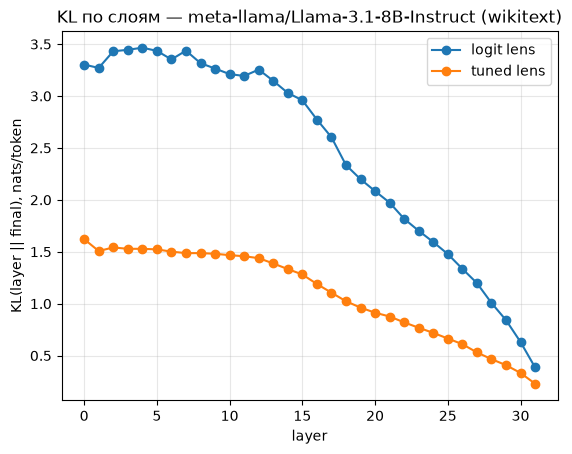

In [15]:
agg = json.load(open(EVAL_DIR / "aggregate_metrics.json"))
layers = sorted(int(k.split("_")[1]) for k in agg["logit"]["kl"])

for name in ["logit", "tuned"]:
    kl = [agg[name]["kl"][f"layer_{l}"] for l in layers]
    plt.plot(layers, kl, marker="o", label=f"{name} lens")

plt.xlabel("layer")
plt.ylabel("KL(layer || final), nats/token")
plt.title(f"KL по слоям — {MODEL_NAME} ({DATA_SOURCE})")
plt.legend()
plt.grid(alpha=.3);

inference

In [7]:
del eval_cfg
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, dtype=torch.bfloat16,
).to("cuda:0").eval()
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

In [8]:
lens = TunedLens.from_model_and_pretrained(
    model, str(TRAIN_DIR),
).to("cuda:0").eval()

In [9]:
prompt = "The capital of France is"
input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to("cuda:0")

with torch.no_grad():
    out = model(input_ids, output_hidden_states=True)

layer = 20
hidden = out.hidden_states[layer][:, -1, :]
logits = lens.forward(hidden, layer)

vis

In [11]:
text_in = "The quick brown fox jumps"
ids = tokenizer.encode(text_in)

traj = PredictionTrajectory.from_lens_and_model(lens, model, ids, tokenizer)
fig = traj.forward_kl().figure(title=f"Forward KL per layer x token — {MODEL_NAME}")
fig.write_html("./llama-tuned_lens-trajectory_plot.html")